# EDA — Parte Específica (TMDB 5000 Movie Dataset)

**Pergunta de pesquisa:** Filmes com orçamento maior têm retorno (receita ÷ orçamento) maior, ou isso varia por gênero?
**Variáveis centrais:** `budget`, `revenue`, `genres`  
**Público-alvo:** gestor de estúdio ou produtora

| Seção | Responsável |
|---|---|
| 1. Estrutural, 2. Faltantes, 3. Outliers, 4. Tratamento | Pessoa 1 |
| 5. Distribucional | Pessoa 2 |
| 6. Relacional / multivariada | Pessoa 3 |

*Células de código marcadas com `# [IA]` foram feitas com apoio de IA (só cálculo/plot). Toda interpretação e decisão é do grupo.*

In [1]:
# [IA] Claude Code – setup e carga dos dados
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))  # rodar o notebook a partir de src/parte_especifica/
from dados import VARS_QUANT, carregar_filmes

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

bruto = pd.read_csv("../../data/parte_especifica/tmdb_5000_movies.csv")  # como vem do Kaggle
df = carregar_filmes(com_creditos=True)                                  # JSON convertido em listas
df.head(3)

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,ano,diretor,elenco_top3
0,237000000,"[Action, Adventure, Fantasy, Science Fiction]",http://www.avatarmovie.com/,19995,"[culture clash, future, space war, space colon...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[Ingenious Film Partners, Twentieth Century Fo...","[US, GB]",2009-12-10,2787965087,162.0,"[en, es]",Released,Enter the World of Pandora.,Avatar,7.2,11800,2009,James Cameron,"[Sam Worthington, Zoe Saldana, Sigourney Weaver]"
1,300000000,"[Adventure, Fantasy, Action]",http://disney.go.com/disneypictures/pirates/,285,"[ocean, drug abuse, exotic island, east india ...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[Walt Disney Pictures, Jerry Bruckheimer Films...",[US],2007-05-19,961000000,169.0,[en],Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,2007,Gore Verbinski,"[Johnny Depp, Orlando Bloom, Keira Knightley]"
2,245000000,"[Action, Adventure, Crime]",http://www.sonypictures.com/movies/spectre/,206647,"[spy, based on novel, secret agent, sequel, mi...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[Columbia Pictures, Danjaq, B24]","[GB, US]",2015-10-26,880674609,148.0,"[fr, en, es, it, de]",Released,A Plan No One Escapes,Spectre,6.3,4466,2015,Sam Mendes,"[Daniel Craig, Christoph Waltz, Léa Seydoux]"


## 1. Pilar estrutural

### 1.1 Dimensões e tipos

In [2]:
# [IA] Claude Code – dimensões e tipos
print("arquivo bruto:", bruto.shape, "| após carga + créditos:", df.shape)
bruto.dtypes.to_frame("dtype")

arquivo bruto: (4803, 20) | após carga + créditos: (4803, 23)


,dtype
budget,int64
genres,str
homepage,str
id,int64
keywords,str
original_language,str
original_title,str
overview,str
popularity,float64
production_companies,str


In [3]:
# [IA] Claude Code – classificação das variáveis (quantitativa x qualitativa) e cardinalidade
tipos = pd.DataFrame({
    "dtype": bruto.dtypes.astype(str),
    "n_unicos": bruto.nunique(),
    "exemplo": bruto.iloc[0].astype(str).str[:60],
})
tipos["natureza"] = np.where(bruto.dtypes.apply(pd.api.types.is_numeric_dtype), "quantitativa", "qualitativa")
tipos.loc["id", "natureza"] = "identificador"
tipos.sort_values("natureza")

,dtype,n_unicos,exemplo,natureza
id,int64,4803,19995,identificador
genres,str,1175,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",qualitativa
homepage,str,1691,http://www.avatarmovie.com/,qualitativa
keywords,str,4222,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",qualitativa
original_language,str,37,en,qualitativa
original_title,str,4801,Avatar,qualitativa
overview,str,4800,"In the 22nd century, a paraplegic Marine is di...",qualitativa
production_companies,str,3697,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",qualitativa
production_countries,str,469,"[{""iso_3166_1"": ""US"", ""name"": ""United States o...",qualitativa
release_date,str,3280,2009-12-10,qualitativa


O arquivo tem [4803] filmes e [20] colunas. As colunas se dividem assim:

Quantitativas: budget, revenue, runtime, popularity, vote_average, vote_count.
Qualitativas (categorias): genres, keywords, original_language, production_companies, production_countries, spoken_languages, status. A coluna release_date é uma data, e dela derivamos ano e decada.
Identificador: id.
Texto livre: title, original_title, overview, tagline, homepage. Não entram na análise.

Para a pergunta de pesquisa, as variáveis centrais são budget, revenue (usadas para calcular o retorno) e genres. Como apoio usamos ano, vote_count e popularity para investigar dados faltantes.

### 1.2 Colunas em JSON

In [4]:
# [IA] Claude Code – como vem no CSV x como fica depois do parsing
print("bruto  :", bruto.loc[0, "genres"][:110], "...")
print("lista  :", df.loc[0, "genres"])
n_itens = pd.DataFrame({c: df[c].str.len() for c in ["genres", "keywords", "production_companies", "production_countries", "spoken_languages"]})
n_itens.describe().T[["mean", "min", "50%", "max"]].rename(columns={"mean": "média de itens por filme"})

bruto  : [{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "na ...
lista  : ['Action', 'Adventure', 'Fantasy', 'Science Fiction']


,média de itens por filme,min,50%,max
genres,2.531751,0.0,2.0,7.0
keywords,7.535707,0.0,6.0,97.0
production_companies,2.847595,0.0,2.0,26.0
production_countries,1.339996,0.0,1.0,12.0
spoken_languages,1.444306,0.0,1.0,9.0


Os gêneros vêm como texto JSON e foram convertidos em listas. Cada filme tem em média [~2,5] gêneros. Avatar, por exemplo, é Ação, Aventura, Fantasia e Ficção Científica ao mesmo tempo.

Isso afeta a pergunta porque os gêneros não são grupos exclusivos: quando calculamos o retorno por gênero, o mesmo filme entra em vários grupos. Por consequência, a soma dos filmes por gênero fica maior que o total, e um blockbuster influencia vários gêneros ao mesmo tempo. Na análise por gênero, cada filme será contado em todos os seus gêneros.

### 1.3 Duplicadas e consistência

In [5]:
# [IA] Claude Code – duplicadas por linha inteira, por id e por título
print("linhas duplicadas:", bruto.duplicated().sum())
print("ids duplicados   :", bruto["id"].duplicated().sum())
dup_titulo = bruto[bruto["title"].duplicated(keep=False)].sort_values("title")
print("títulos repetidos:", dup_titulo["title"].nunique())
dup_titulo[["id", "title", "release_date", "budget", "revenue"]]

linhas duplicadas: 0
ids duplicados   : 0
títulos repetidos: 3


,id,title,release_date,budget,revenue
1359,268,Batman,1989-06-23,35000000,411348924
4267,2661,Batman,1966-07-30,1377800,0
3647,39269,Out of the Blue,1980-05-01,0,0
3693,10844,Out of the Blue,2006-10-12,0,0
972,72710,The Host,2013-03-22,44000000,63327201
2877,1255,The Host,2006-07-27,11000000,88489643


In [6]:
# [IA] Claude Code – checagens de consistência
print("status:"); print(bruto["status"].value_counts(), "\n")
print("release_date fora de [1900, 2017]:", ((df["ano"] < 1900) | (df["ano"] > 2017)).sum())
print("vote_average fora de [0, 10]:", ((bruto["vote_average"] < 0) | (bruto["vote_average"] > 10)).sum())
print("valores negativos em budget/revenue/runtime:", (bruto[["budget", "revenue", "runtime"]] < 0).sum().sum())

status:
status
Released           4795
Rumored               5
Post Production       3
Name: count, dtype: int64 

release_date fora de [1900, 2017]: 0
vote_average fora de [0, 10]: 0
valores negativos em budget/revenue/runtime: 0


Não há linhas duplicadas nem id repetido. Existem [3] títulos repetidos, mas são filmes diferentes (refilmagens ou homônimos, com datas de lançamento distintas), então todos foram mantidos.

Quase todos os filmes têm status “Released”. Os [8] filmes “Rumored” ou “Post Production” ainda não tinham sido lançados quando os dados foram coletados, então não podem ter receita real e serão excluídos da análise financeira.

Não há anos fora do intervalo esperado, notas fora de 0 a 10 nem valores negativos.

## 2. Dados faltantes

### 2.1 Ausência explícita (NaN / vazio)

In [7]:
# [IA] Claude Code – contagem de NaN por coluna
na = bruto.isna().sum()
pd.DataFrame({"n_faltantes": na, "pct": (100 * na / len(bruto)).round(2)}).query("n_faltantes > 0").sort_values("n_faltantes", ascending=False)

,n_faltantes,pct
homepage,3091,64.36
tagline,844,17.57
overview,3,0.06
runtime,2,0.04
release_date,1,0.02


In [8]:
# [IA] Claude Code – listas vazias (ex.: '[]' em genres) também são ausência
pd.Series({c: (df[c].str.len() == 0).sum() for c in ["genres", "keywords", "production_companies", "production_countries", "spoken_languages"]}, name="listas_vazias").to_frame()

,listas_vazias
genres,28
keywords,412
production_companies,351
production_countries,174
spoken_languages,86


### 2.2 Ausência disfarçada (zeros que significam “não informado”)

In [9]:
# [IA] Claude Code – zeros em colunas onde 0 não é um valor plausível
zeros = pd.Series({c: (bruto[c] == 0).sum() for c in ["budget", "revenue", "runtime", "vote_count", "popularity"]})
pd.DataFrame({"n_zeros": zeros, "pct": (100 * zeros / len(bruto)).round(2)})

,n_zeros,pct
budget,1037,21.59
revenue,1427,29.71
runtime,35,0.73
vote_count,62,1.29
popularity,1,0.02


In [10]:
# [IA] Claude Code – budget = 0 e revenue = 0 aparecem juntos?
pd.crosstab(bruto["budget"] == 0, bruto["revenue"] == 0, rownames=["budget == 0"], colnames=["revenue == 0"], margins=True)

revenue == 0,False,True,All
budget == 0,,,
False,3229,537,3766
True,147,890,1037
All,3376,1427,4803


### 2.3 Investigando o mecanismo de ausência
Comparamos os filmes **com** e **sem** informação financeira em outras variáveis. Se os grupos forem muito diferentes, a ausência não é aleatória (não é MCAR).

In [11]:
# [IA] Claude Code – perfil dos filmes com e sem budget/revenue informados
df["financeiro_informado"] = np.where((df["budget"] > 0) & (df["revenue"] > 0), "informado", "faltando")
perfil = df.groupby("financeiro_informado")[["popularity", "vote_count", "vote_average", "runtime", "ano"]].median()
perfil["n_filmes"] = df["financeiro_informado"].value_counts()
perfil

,popularity,vote_count,vote_average,runtime,ano,n_filmes
financeiro_informado,,,,,,
faltando,3.752020,38.0,5.9,98.0,2006.0,1574
informado,20.410354,471.0,6.3,107.0,2005.0,3229


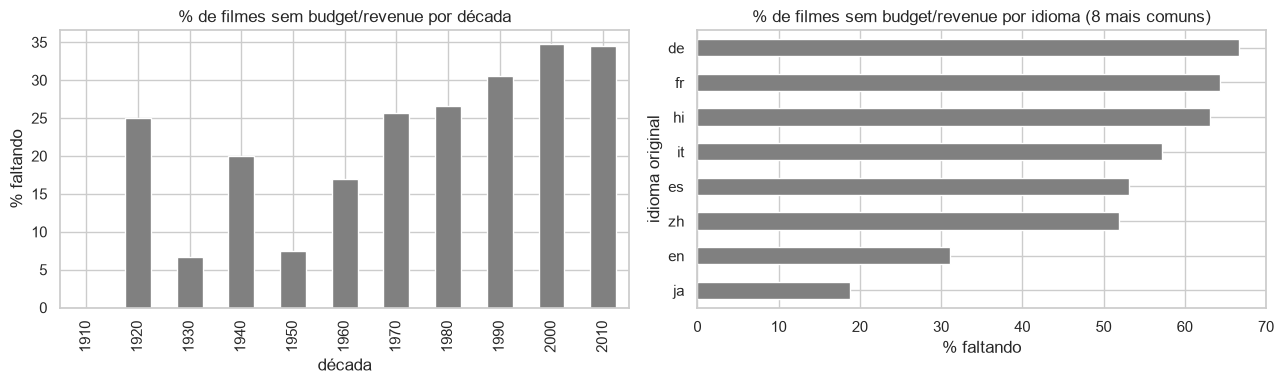

In [12]:
# [IA] Claude Code – proporção de dados financeiros faltando por década e por idioma original
df["decada"] = (df["ano"] // 10 * 10).astype("Int64")
falta = df["financeiro_informado"].eq("faltando")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
falta.groupby(df["decada"]).mean().mul(100).plot.bar(ax=axes[0], color="gray")
axes[0].set(title="% de filmes sem budget/revenue por década", xlabel="década", ylabel="% faltando")
top_idiomas = df["original_language"].value_counts().head(8).index
falta[df["original_language"].isin(top_idiomas)].groupby(df["original_language"]).mean().mul(100).sort_values().plot.barh(ax=axes[1], color="gray")
axes[1].set(title="% de filmes sem budget/revenue por idioma (8 mais comuns)", xlabel="% faltando", ylabel="idioma original")
plt.tight_layout(); plt.show()

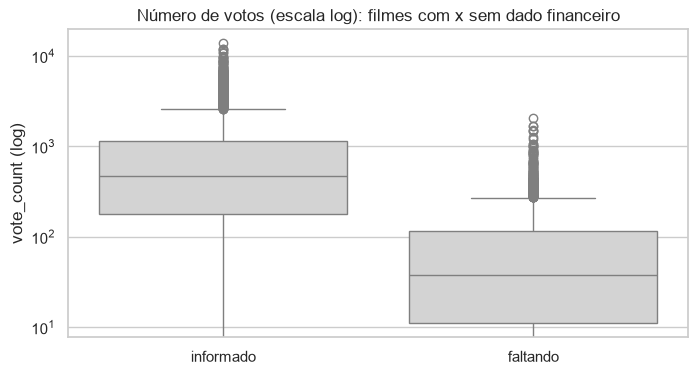

In [13]:
# [IA] Claude Code – distribuição de popularidade: com x sem dado financeiro
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="financeiro_informado", y="vote_count", ax=ax, color="lightgray")
ax.set(yscale="log", title="Número de votos (escala log): filmes com x sem dado financeiro", xlabel="", ylabel="vote_count (log)")
plt.show()

> **Mecanismo de ausência, por problema.** Usamos três categorias: **MCAR** (o dado falta por acaso, sem relação com nenhuma variável), **MAR** (a ausência é explicada por outras variáveis observadas, como popularidade ou idioma) e **MNAR** (a ausência depende do próprio valor que falta).

| Problema | Mecanismo | Por quê | Tratamento |
|---|---|---|---|
| `budget`/`revenue` = 0 | MAR (com possível MNAR) | Os filmes sem dado financeiro têm muito menos votos (mediana de 38 contra 471) e são mais frequentemente de idioma original diferente do inglês (57% de ausência contra 31% nos filmes em inglês). A ausência não está concentrada em filmes antigos: ela é até um pouco maior nas décadas de 2000 e 2010. Além disso, filmes pequenos ou que fracassaram tendem a não divulgar orçamento e bilheteria. | Excluir da análise de retorno. Não imputar, porque estimar receita seria inventar justamente a resposta da pergunta. |
| `runtime` = 0 ou NaN | MCAR | São apenas 37 casos (35 zeros e 2 NaN), sem padrão aparente; provavelmente cadastro incompleto. | Converter 0 em NaN. Não afeta a pergunta. |
| `vote_count` = 0 | MAR | São 62 filmes muito obscuros. Nesses casos, `vote_average` = 0 não é uma nota real. | Transformar `vote_average` em NaN quando `vote_count` = 0. |
| `homepage` vazio | MAR | Faltam 3091 valores (64%). Filmes antigos são anteriores à internet e muitos filmes pequenos nunca tiveram site; a ausência é estrutural. | Descartar a coluna, que é irrelevante para a pergunta. |
| `tagline` vazio | MCAR/MAR | Faltam 844 valores; nem todo filme tem slogan. | Manter sem tratamento, pois a coluna não entra na análise. |
| `overview` / `release_date` vazios | MCAR | Apenas 3 e 1 casos. | Remover a linha sem data, que é necessária para `ano`/`decada`. Ignorar `overview`. |
| `genres` vazio | MCAR | Apenas 28 filmes. | Excluir somente da análise por gênero. |

**Consequência para a análise:** ao excluir os filmes sem dados financeiros, a base para a pergunta de pesquisa fica com 3229 filmes antes do tratamento de outliers (67,2% do total). Como essa ausência **não é aleatória**, a base restante é composta principalmente por filmes mais populares e de língua inglesa. Portanto, as conclusões sobre retorno valem para esse grupo de filmes, e não para o cinema como um todo.

## 3. Outliers

### 3.1 Regra do IQR nas variáveis quantitativas

In [14]:
# [IA] Claude Code – tabela de outliers por IQR (1,5·IQR), ignorando zeros de budget/revenue
def resumo_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (s < lo) | (s > hi)
    return pd.Series({"n": s.size, "limite_inf": lo, "limite_sup": hi, "n_outliers": fora.sum(), "pct": round(100 * fora.mean(), 2), "max": s.max()})

base = {c: df[c] for c in VARS_QUANT}
base["budget"] = df.loc[df["budget"] > 0, "budget"]
base["revenue"] = df.loc[df["revenue"] > 0, "revenue"]
pd.DataFrame({c: resumo_iqr(s.dropna()) for c, s in base.items()}).T

,n,limite_inf,limite_sup,n_outliers,pct,max
budget,3766.0,-5.500000e+07,1.130000e+08,245.0,6.51,3.800000e+08
revenue,3376.0,-1.718654e+08,3.273834e+08,299.0,8.86,2.787965e+09
popularity,4803.0,-3.080008e+01,6.378166e+01,275.0,5.73,8.755813e+02
runtime,4801.0,5.800000e+01,1.540000e+02,182.0,3.79,3.380000e+02
vote_average,4803.0,3.800000e+00,8.600000e+00,156.0,3.25,1.000000e+01
vote_count,4803.0,-9.705000e+02,1.761500e+03,504.0,10.49,1.375200e+04


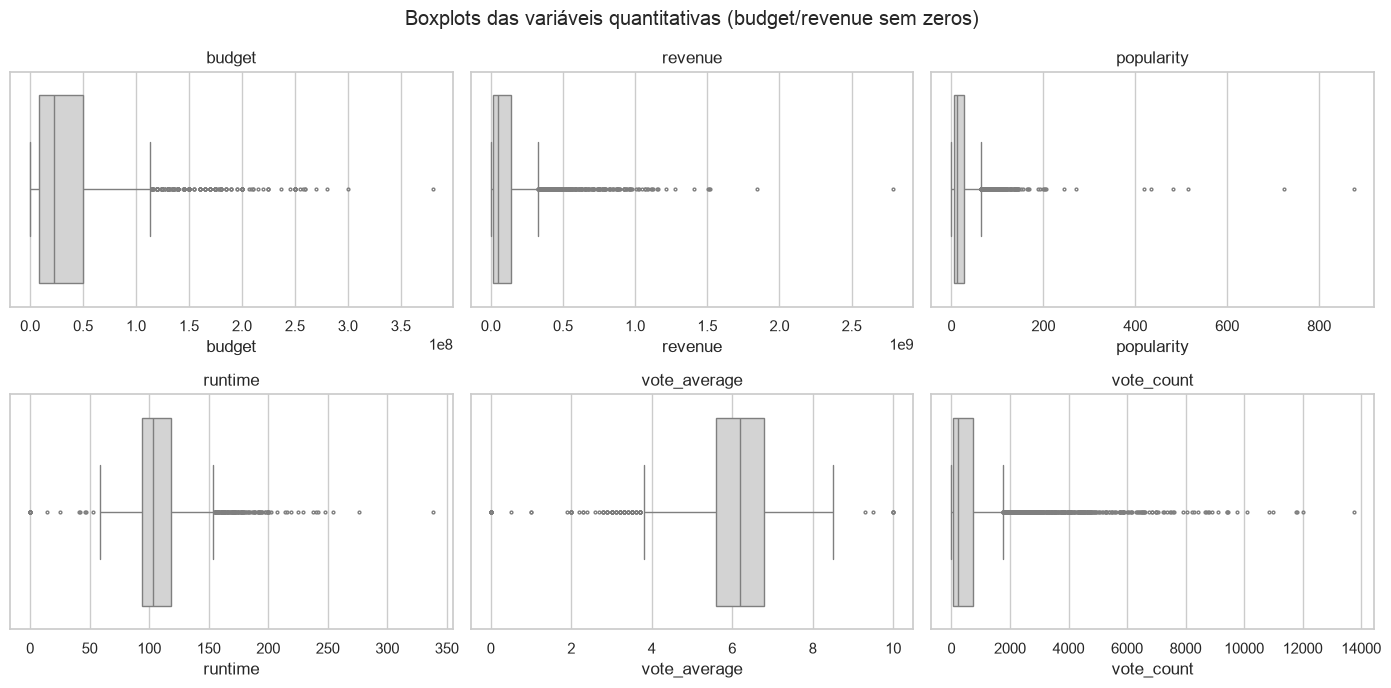

In [15]:
# [IA] Claude Code – boxplots (budget/revenue só > 0)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (c, s) in zip(axes.ravel(), base.items()):
    sns.boxplot(x=s.dropna(), ax=ax, color="lightgray", fliersize=2)
    ax.set(title=c, xlabel=c)
plt.suptitle("Boxplots das variáveis quantitativas (budget/revenue sem zeros)"); plt.tight_layout(); plt.show()

### 3.2 Valores implausíveis (possíveis erros de digitação/unidade)

In [16]:
# [IA] Claude Code – orçamentos e receitas positivos mas muito baixos
suspeitos = df[((df["budget"] > 0) & (df["budget"] < 1000)) | ((df["revenue"] > 0) & (df["revenue"] < 1000))]
print("filmes com budget ou revenue entre 1 e 999:", len(suspeitos))
suspeitos[["title", "ano", "budget", "revenue", "vote_count"]].sort_values("budget")

filmes com budget ou revenue entre 1 e 999: 44


,title,ano,budget,revenue,vote_count
3523,Khiladi 786,2012,0,126,11
3541,Irreversible,2002,0,792,538
2806,Tae Guk Gi: The Brotherhood of War,2004,0,15,133
2848,My Baby's Daddy,2004,0,51,15
3503,Lake of Fire,2006,0,25,10
3428,Bats,1999,0,10,35
3278,When Did You Last See Your Father?,2007,0,92,13
4424,Fear Clinic,2014,1,0,42
4369,Slam,1998,1,0,7
4293,The Algerian,2015,1,0,0


In [17]:
# [IA] Claude Code – durações extremas
print("runtime == 0:", (df["runtime"] == 0).sum())
df.loc[df["runtime"] > 0].nlargest(8, "runtime")[["title", "ano", "runtime", "genres"]]

runtime == 0: 35


,title,ano,runtime,genres
2384,Carlos,2010,338.0,"[Crime, Drama, Thriller, History]"
2631,The Company,2007,276.0,[Drama]
1922,Gettysburg,1993,254.0,"[War, Drama, History]"
1125,Cleopatra,1963,248.0,"[Drama, History, Romance]"
2373,Hamlet,1996,242.0,[Drama]
3510,Emma,2009,240.0,"[Romance, Comedy, Drama]"
3813,Gone with the Wind,1939,238.0,"[Drama, Romance, War]"
1663,Once Upon a Time in America,1984,229.0,"[Drama, Crime]"


### 3.3 Efeito na variável da pergunta: retorno = revenue ÷ budget

In [18]:
# [IA] Claude Code – retorno só para quem tem os dois valores > 0
fin = df[(df["budget"] > 0) & (df["revenue"] > 0)].copy()
fin["retorno"] = fin["revenue"] / fin["budget"]
print(fin["retorno"].describe().round(2))
fin.nlargest(10, "retorno")[["title", "ano", "budget", "revenue", "retorno"]]

count       3229.00
mean        2954.82
std       150610.10
min            0.00
25%            1.02
50%            2.30
75%            4.42
max      8500000.00
Name: retorno, dtype: float64


,title,ano,budget,revenue,retorno
4238,Modern Times,1936,1,8500000,8.500000e+06
3137,Nurse 3-D,2013,10,10000000,1.000000e+06
4577,Paranormal Activity,2007,15000,193355800,1.289039e+04
4582,Tarnation,2003,218,1162014,5.330339e+03
4496,The Blair Witch Project,1999,60000,248000000,4.133333e+03
4724,Eraserhead,1977,10000,7000000,7.000000e+02
4788,Pink Flamingos,1972,12000,6000000,5.000000e+02
4742,Super Size Me,2004,65000,28575078,4.396166e+02
4723,The Gallows,2015,100000,42664410,4.266441e+02
4514,Open Water,2004,130000,54667954,4.205227e+02


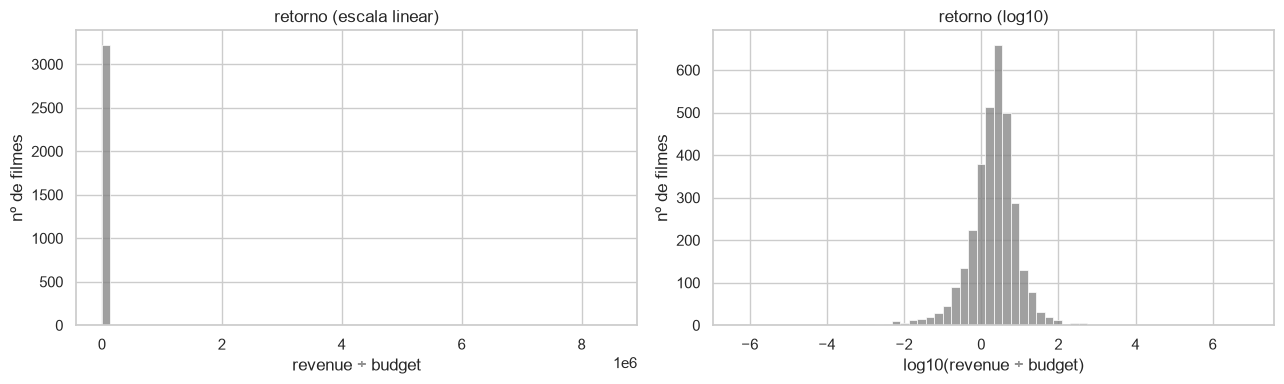

In [19]:
# [IA] Claude Code – distribuição do retorno em escala linear x log
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(fin["retorno"], bins=60, ax=axes[0], color="gray")
axes[0].set(title="retorno (escala linear)", xlabel="revenue ÷ budget", ylabel="nº de filmes")
sns.histplot(np.log10(fin["retorno"]), bins=60, ax=axes[1], color="gray")
axes[1].set(title="retorno (log10)", xlabel="log10(revenue ÷ budget)", ylabel="nº de filmes")
plt.tight_layout(); plt.show()

> **Outlier não é sinônimo de erro.** A regra do IQR marca como outlier tudo que fica muito longe do centro dos dados. Orçamento e receita são muito assimétricos (poucos filmes gigantes e muitos pequenos), então o IQR marca 245 orçamentos (6,5%) e 299 receitas (8,9%) como outliers. Isso é característica das variáveis, e não erro. Por isso, em cada caso, perguntamos: **esse valor é possível na vida real?**

| Caso | Erro ou legítimo? | Decisão | Justificativa |
|---|---|---|---|
| budget/revenue entre 1 e 999 | Erro (com uma exceção) | Excluir da análise de retorno | São 44 filmes, 18 deles na base de retorno. Valores como orçamento de US$ 1 (*Modern Times*) ou US$ 10 (*Nurse 3-D*) indicam cadastro na unidade errada (milhões em vez de dólares) e geram retornos absurdos, de até 8,5 milhões de vezes. A exceção é *Tarnation*, cujo orçamento de US$ 218 é real; como é um único caso, aceitamos excluí-lo junto para manter uma regra simples e reprodutível. |
| runtime == 0 | Erro (ausência disfarçada) | Converter para NaN | São 35 filmes, e nenhum filme tem 0 minutos. |
| Blockbusters (budget/revenue altíssimos) | Legítimo | Manter | Filmes como *Piratas do Caribe: Navegando em Águas Misteriosas* (US$ 380 milhões de orçamento) e *Avatar* (US$ 2,8 bilhões de receita) realmente custaram e faturaram isso. Removê-los apagaria justamente os filmes de orçamento alto que a pergunta quer comparar. |
| Retornos extremos | Legítimo (após excluir os valores suspeitos) | Manter | Depois de excluir os orçamentos implausíveis, os maiores retornos são reais: filmes de terror e independentes baratíssimos que viraram fenômeno, como *Atividade Paranormal* (cerca de 12.900 vezes o orçamento) e *A Bruxa de Blair* (cerca de 4.100 vezes). Eles fazem parte da resposta à pergunta. |

**Distribuição do retorno:** após o tratamento, a base de retorno tem 3211 filmes. O retorno é extremamente assimétrico: a mediana é 2,3 (o filme típico fatura pouco mais que o dobro do que custou), metade dos filmes fica entre 1,03 e 4,42, cerca de 24% dão prejuízo (retorno menor que 1) e apenas 23 filmes passam de 100 vezes o orçamento. Por causa desses extremos, a média (11,1) fica quase cinco vezes maior que a mediana e não representa o filme típico. Na escala log, a distribuição fica bem mais simétrica. Por isso, nas próximas etapas, recomendamos **usar a mediana (e não a média) e escala log nos gráficos de retorno**.

## 4. Tratamento final — `tratar(df)`
As decisões das seções 2 e 3 foram reunidas no dicionário `DECISOES` e aplicadas pela função `tratar(df)` em `dados.py`. Aqui comparamos a base antes e depois do tratamento e testamos uma alternativa sem o limite para valores implausíveis.

In [20]:
# [IA] Claude Code – aplicar o tratamento atual (DECISOES de dados.py)
from dados import DECISOES, tratar
print("DECISOES atuais:", DECISOES, "\n")
tratado = tratar(df, verbose=True)
print("\nlinhas:", len(df), "->", len(tratado))

DECISOES atuais: {'zeros_financeiros': 'nan', 'limite_implausivel': 1000, 'runtime_zero': 'nan', 'sem_votos': 'nan', 'remover_colunas': ['homepage'], 'retorno_so_lancados': True, 'remover_sem_data': True} 

linhas sem data removidas        1
budget -> NaN                    1068
revenue -> NaN                   1448
runtime 0 -> NaN                 34
vote_average sem votos -> NaN    61
colunas removidas                ['homepage']
não lançados fora do retorno     1
filmes com retorno calculável    3210

linhas: 4803 -> 4802


In [21]:
alternativa = tratar(df, {"limite_implausivel": None}, verbose=True)

linhas sem data removidas        1
budget -> NaN                    1036
revenue -> NaN                   1426
runtime 0 -> NaN                 34
vote_average sem votos -> NaN    61
colunas removidas                ['homepage']
não lançados fora do retorno     1
filmes com retorno calculável    3228


In [22]:
# [IA] Claude Code – antes x depois nas variáveis quantitativas e no retorno
cols = ["budget", "revenue", "runtime", "vote_average", "retorno"]
comparacao = pd.concat({
    "antes (bruto)": bruto[["budget", "revenue", "runtime", "vote_average"]].describe().T,
    "depois (DECISOES)": tratado[cols].describe().T,
    "alternativa": alternativa[cols].describe().T,
}, axis=0)[["count", "mean", "50%", "max"]]
comparacao.round(2)

count          mean         50%           max
antes (bruto)     budget        4803.0  2.904504e+07  15000000.0  3.800000e+08
                  revenue       4803.0  8.226064e+07  19170001.0  2.787965e+09
                  runtime       4801.0  1.068800e+02       103.0  3.380000e+02
                  vote_average  4803.0  6.090000e+00         6.2  1.000000e+01
depois (DECISOES) budget        3734.0  3.736029e+07  23300000.0  3.800000e+08
                  revenue       3354.0  1.177990e+08  52298389.0  2.787965e+09
                  runtime       4766.0  1.076600e+02       104.0  3.380000e+02
                  vote_average  4741.0  6.170000e+00         6.2  1.000000e+01
                  retorno       3210.0  1.114000e+01         2.3  1.289039e+04
alternativa       budget        3766.0  3.704284e+07  23000000.0  3.800000e+08
                  revenue       3376.0  1.170314e+08  51751835.0  2.787965e+09
                  runtime       4766.0  1.076600e+02       104.0  3.380000e+02
                  vote_average  4741.0  6.170000e+00         6.2  1.000000e+01
                  retorno       3228.0  2.955740e+03         2.3  8.500000e+06

**Resumo do antes × depois**

**Quanto mudou.** Apenas **uma linha foi removida**: o único filme sem data de lançamento (*America Is Still the Place*), que também não tinha orçamento nem receita. A base passou de 4803 para 4802 filmes. Nos demais casos, os valores inválidos viraram NaN e o filme continua no dataset, saindo apenas das contas que usam aquela coluna:
- `budget`: 1068 valores viraram NaN (1036 zeros e 32 valores implausíveis abaixo de US$ 1000), restando 3734 válidos;
- `revenue`: 1448 valores viraram NaN (1426 zeros e 22 implausíveis), restando 3354;
- `runtime`: 34 zeros viraram NaN (restam 4766 válidos, contando os 2 NaN originais);
- `vote_average`: 61 notas iguais a 0 viraram NaN, porque esses filmes não tinham nenhum voto (restam 4741);
- a coluna `homepage` foi descartada, e 1 filme não lançado ficou sem retorno calculado.

**Média e mediana de `budget` e `revenue`.**

| Variável | Média antes | Média depois | Mediana antes | Mediana depois |
|---|---|---|---|---|
| `budget` | US$ 29,0 mi | US$ 37,4 mi (+29%) | US$ 15,0 mi | US$ 23,3 mi (+55%) |
| `revenue` | US$ 82,3 mi | US$ 117,8 mi (+43%) | US$ 19,2 mi | US$ 52,3 mi (+173%) |

As duas medidas subiram porque os zeros puxavam os valores para baixo sem representar orçamentos ou receitas reais. A **mediana mudou mais**. Na média, um zero não acrescenta nada à soma, apenas aumenta a contagem; ao retirá-los, a mesma soma é dividida por menos filmes, e a média sobe aproximadamente na proporção de filmes retirados (4803 ÷ 3354 ≈ 1,43, ou seja, cerca de +43% em `revenue`). Já a mediana depende da posição dos valores: com cerca de 30% de zeros em `revenue`, o "meio" da lista caía em filmes de receita baixa. Sem os zeros, o meio passa a ser um filme bem maior, por isso o salto de 173%.

**O `max` do retorno.** Sem o limite para valores implausíveis (alternativa), o retorno máximo é de **8,5 milhões de vezes** o orçamento (*Modern Times*, com orçamento cadastrado como US$ 1), e a média do retorno chega a cerca de 2.956. Com o limite de US$ 1000 (tratamento adotado), o máximo cai para **cerca de 12.900 vezes** (*Atividade Paranormal*, um caso real) e a média para 11,1. A mediana fica em 2,3 nos dois cenários. Ou seja: apenas 18 filmes com valores implausíveis bastavam para distorcer completamente a média e o máximo, sem afetar a mediana. Isso confirma que eram erros de cadastro e reforça o uso da mediana nas próximas etapas.

**Tamanho e representatividade da amostra.** A pergunta de pesquisa vai trabalhar com **3210 filmes** com retorno válido (67% da base original). É uma amostra grande o suficiente para comparar faixas de orçamento e os gêneros mais comuns, mas gêneros raros terão poucos filmes e precisarão do corte mínimo combinado (pelo menos 30 filmes por gênero). Porém, a amostra **não representa todos os filmes**: como vimos na seção 2.3, os filmes sem dado financeiro são principalmente os menos populares e os de idioma diferente do inglês. As conclusões valem para filmes conhecidos, majoritariamente de língua inglesa.

**Problemas que o tratamento não resolveu.**
- **Assimetria:** o retorno continua extremamente assimétrico (metade dos filmes fica entre 1,03 e 4,42, mas 23 passam de 100 vezes o orçamento). O tratamento não deve "corrigir" isso, porque os extremos restantes são reais; a solução está na análise, com mediana e escala log.
- **Inflação:** os valores estão em dólares nominais, sem correção. Um orçamento de 1980 não é comparável a um de 2015. O retorno, por ser uma razão entre receita e orçamento do mesmo filme, é pouco afetado, mas comparações diretas de `budget` e `revenue` entre décadas ficam distorcidas.
- **Viés de seleção (MNAR):** se filmes que fracassaram tendem a não divulgar bilheteria, o retorno da amostra pode estar superestimado. Isso não tem como ser corrigido com os dados disponíveis.
- **Exclusão de um caso real:** o limite de US$ 1000 também excluiu *Tarnation*, cujo orçamento de US$ 218 é verdadeiro. Aceitamos essa perda para manter uma regra simples e reprodutível.
- **Gêneros sobrepostos:** como um filme pode ter vários gêneros, as comparações por gênero não são entre grupos independentes.

## 5. Pilar distribucional — *Pessoa 2*

## 6. Pilar relacional / multivariado — *Pessoa 3*